# Experiment 01 — Myocardial Diffusion Model

## Setup

This project requires Python 3.7 or above:

In [1]:
import sys
assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [2]:
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

**Warning**: the latest TensorFlow versions are based on Keras 3. Unfortunately it's much harder for this, in particular adding custom losses using the functional API is not implemented yet. So for this Model I've had to revert to Keras 2. To do that, I set the `TF_USE_LEGACY_KERAS` environment variable to `"1"` and import the `tf_keras` package. This ensures that `tf.keras` points to `tf_keras`, which is Keras 2.*.

In [3]:
import importlib
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras

I0000 00:00:1792176034.759825    1785 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792176035.060064    1785 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792176036.669710    1785 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


And TensorFlow ≥ 2.8:

In [4]:
import tensorflow as tf
assert version.parse(tf.__version__) >= version.parse("2.8.0")

Let's define the default font sizes to make the figures prettier:

In [5]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

Create the Experiment 01 results/figures folder and define `save_fig()` to store this experiment's plots alongside its checkpoint and predictions:

In [6]:
from pathlib import Path

project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next(
    (path.resolve() for path in project_candidates
     if (path / "myocardial_data.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate the myocardial-gdm project root")

DIFFUSION_RESULTS_DIR = PROJECT_DIR / "experiments" / "01_diffusion" / "results"
IMAGES_PATH = DIFFUSION_RESULTS_DIR / "figures"
CHECKPOINT_PATH = DIFFUSION_RESULTS_DIR / "checkpoints" / "myocardial_conditional_diffusion_v_prediction.keras"
HISTORY_PATH = DIFFUSION_RESULTS_DIR / "history" / "myocardial_training_history_v_prediction.csv"
PREDICTIONS_PATH = DIFFUSION_RESULTS_DIR / "predictions" / "run_03_v_prediction"
for output_dir in (IMAGES_PATH, CHECKPOINT_PATH.parent, HISTORY_PATH.parent, PREDICTIONS_PATH):
    output_dir.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=256):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

This chapter can be very slow without a GPU, so let's make sure there's one, or else issue a warning:

In [7]:
import sys, os
print("Python Executable:", sys.executable)
print("Platform:", sys.platform)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH", "NOT SET"))

Python Executable: /home/molham/miniconda3/envs/myocardial-gdm/bin/python
Platform: linux
LD_LIBRARY_PATH: /usr/lib/wsl/lib:/home/molham/miniconda3/envs/myocardial-gdm/lib/python3.10/site-packages/tensorflow:


In [8]:
if not tf.config.list_physical_devices('GPU'):
    print("No GPU was detected. Neural nets can be very slow without a GPU.")
    if "google.colab" in sys.modules:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if "kaggle_secrets" in sys.modules:
        print("Go to Settings > Accelerator and select GPU.")
else:
    print("GPU detected. You are good to go!")

GPU detected. You are good to go!


## MyoPS data and plotting setup

Use only the still 3D volumes in `MyoPS_train` and `MyoPS_val`; pair LGE with the available C0 (static bSSFP) or T2 target within each case. Cases missing a target are excluded from that modality's supervised loss but can still be used for inference.


In [9]:
import os
import sys
import numpy as np
from pathlib import Path

project_candidates = [Path.cwd(), *Path.cwd().parents]
module_dir = next(
    (path.resolve() for path in project_candidates
     if (path / "myocardial_data.py").is_file()),
    None,
)
if module_dir is None:
    raise FileNotFoundError("Could not locate myocardial_data.py")
sys.path.insert(0, str(module_dir))
import myocardial_data
importlib.reload(myocardial_data)

from myocardial_data import (
    TARGET_MODALITIES,
    build_conditional_diffusion_model,
    find_paired_cases,
    generate_conditioned,
    load_aligned_pair,
    load_lge_volume,
    make_paired_dataset,
    resize_normalized_image,
    restore_normalized_image,
    paired_case_counts,
    synthesize_volume,
)

data_root_candidates = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("MYO_DATA_ROOT"):
    data_root_candidates.insert(0, Path(os.environ["MYO_DATA_ROOT"]).expanduser())
DATA_ROOT = next(
    (path.resolve() for path in data_root_candidates
     if (path / "Myo_train" / "MyoPS_train").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Set MYO_DATA_ROOT to the directory containing Myo_train and Myo_val"
    )

TRAIN_PAIRS = find_paired_cases(DATA_ROOT / "Myo_train" / "MyoPS_train")
VALID_PAIRS = find_paired_cases(DATA_ROOT / "Myo_val" / "MyoPS_val")
print("Training paired cases:", dict(paired_case_counts(TRAIN_PAIRS)))
print("Validation paired cases:", dict(paired_case_counts(VALID_PAIRS)))

def plot_multiple_images(images, n_cols=8):
    images = np.asarray(images)
    if images.ndim == 4 and images.shape[-1] == 1:
        images = images[..., 0]
    n_images = len(images)
    n_rows = (n_images - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * 1.5, n_rows * 1.5))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="gray", vmin=-1, vmax=1)
        plt.axis("off")


Training paired cases: {'C0': 104, 'T2': 80}
Validation paired cases: {'C0': 15, 'T2': 15}


# Diffusion Models

For each paired training slice, the forward diffusion process adds Gaussian noise to the target (C0 or T2) image. The denoiser receives that noisy target, its aligned LGE source slice, the diffusion time, and the requested target modality, then predicts the added noise. This makes generation conditional on both LGE anatomy and whether C0/bSSFP or T2 is requested.

The [DDPM paper](https://arxiv.org/abs/2006.11239) increased $\beta_t$ from $\beta_1$ = 0.0001 to $\beta_T = $0.02 ($T$ is the max step), but the [Improved DDPM paper](https://arxiv.org/pdf/2102.09672.pdf) suggested using the following $\cos^2(\ldots)$ schedule instead, which gradually decreases $\bar{\alpha_t} = \prod_{i=0}^{t} \alpha_i$ from 1 to 0, where $\alpha_t = 1 - \beta_t$:

In [10]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # add α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ , α̅ₜ , βₜ for t = 0 to T

np.random.seed(42)  # extra code – for reproducibility
T = 1000
alpha, alpha_cumprod, beta = variance_schedule(T)

Use $T = 1,000$ for training. The variable `alpha` contains $\alpha_0, ..., \alpha_T$, and `alpha_cumprod` contains $\bar{\alpha_0}, ..., \bar{\alpha_T}$. Synthesis uses 100 deterministic DDIM steps by default rather than evaluating all 1,000 reverse steps.

Let's plot `alpha_cumprod`:

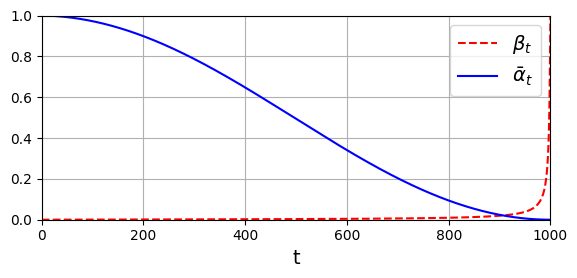

In [11]:
# extra code – this cell generates and saves Figure 17–21
plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1])
plt.grid(True)
plt.xlabel(r"t")
plt.legend()
save_fig("variance_schedule_plot")
plt.show()

The paired input pipeline streams slices from disk and adds noise to each target slice at an independently sampled time between 1 and $T$. For Run 3, it returns the conditional inputs and velocity (`v`) targets; the default pipeline remains epsilon prediction for backward compatibility:

* The inputs contain the noisy target, aligned LGE source, time index, and target-modality ID. Noise is added in one step using equation (4) from the DDPM paper.
* The target is the noise that was used to produce the noisy images.

In [12]:
# The paired MyoPS dataset builder adds diffusion noise after resizing paired slices.

Now let's prepare a `tf.data.Dataset` for training, and one for validation.

In [13]:
IMAGE_SIZE = 128
BATCH_SIZE = 16
tf.random.set_seed(43)
train_set = make_paired_dataset(
    TRAIN_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, shuffle=True, prediction_type="v",
)
valid_set = make_paired_dataset(
    VALID_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, prediction_type="v",
)

I0000 00:00:1792176038.536449    1785 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9513 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


As a quick sanity check, let's take a look at a few training samples, along with the corresponding noise to predict, and the original images (which we get by subtracting the appropriately scaled noise from the appropriately scaled noisy image):

I0000 00:00:1792176039.780075    4466 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


LGE conditions


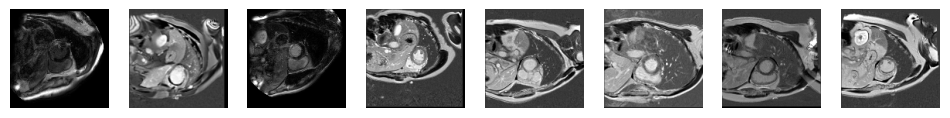

Target modalities: [b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'T2', b'C0 / bSSFP', b'C0 / bSSFP']
Original target images reconstructed from the forward process


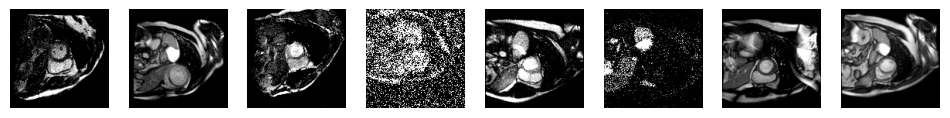

Time steps: [405 312 441 991 443 657 308 151]
Noisy images


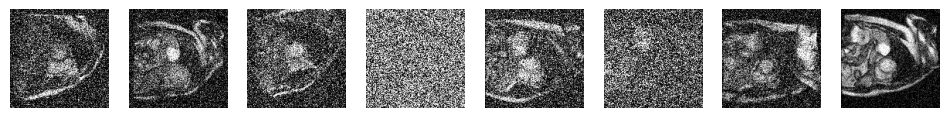

Noise to predict


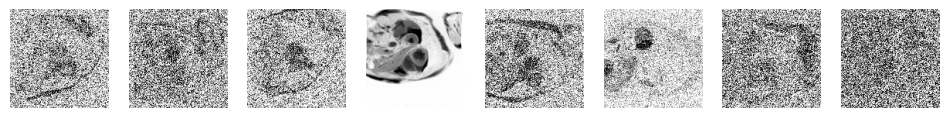

In [14]:
# extra code – just a quick sanity check

def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]  # get the first batch
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("LGE conditions")
plot_multiple_images(X_dict["X_condition"][:8].numpy())
plt.show()
modality_names = tf.gather(tf.constant(["C0 / bSSFP", "T2"]), X_dict["modality"][:8])
print("Target modalities:", modality_names.numpy().tolist())
print("Original target images reconstructed from the forward process")
plot_multiple_images(X_original[:8].numpy())
plt.show()
print("Time steps:", X_dict["time"].numpy()[:8])
print("Noisy images")
plot_multiple_images(X_dict["X_noisy"][:8].numpy())
plt.show()
print("Noise to predict")
plot_multiple_images(Y_noise[:8].numpy())
plt.show()

The U-Net jointly processes the noisy target and the LGE condition. Sinusoidal timestep encodings and a learned C0/T2 modality embedding are injected into its down- and up-sampling blocks.

In [15]:
embed_size = 64

In Run 3, the model predicts the velocity (`v`) target for a 128 × 128 target slice. It uses the LGE slice as a spatial condition, and a two-entry modality embedding distinguishes C0/bSSFP synthesis from T2 synthesis. The three down/up-sampling stages use skip connections to retain spatial detail.

In [16]:
def build_diffusion_model():
    return build_conditional_diffusion_model(
        timesteps=T, image_size=IMAGE_SIZE, embedding_size=embed_size
    )

Build the Experiment 01 U-Net used for the controlled Run 3 prediction-parameterization test.

In [ ]:
tf.random.set_seed(42)
model = build_diffusion_model()
model.compile(
    loss=tf.keras.losses.Huber(),
    optimizer=tf.keras.optimizers.Nadam(),
    metrics=["accuracy"],
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    str(CHECKPOINT_PATH),
    monitor="val_loss",
    save_best_only=True,
)
training_log_cb = tf.keras.callbacks.CSVLogger(
    str(HISTORY_PATH), append=False
)

history = model.fit(
    train_set,
    validation_data=valid_set,
    epochs=100,
    callbacks=[checkpoint_cb, training_log_cb],
)
model.load_weights(str(CHECKPOINT_PATH))

Epoch 1/100


E0000 00:00:1792176050.279381    1785 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape ingradient_tape/huber_loss/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792176056.876412    4400 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792176059.664221    4403 service.cc:153] XLA service 0x741d62878120 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792176059.664261    4403 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 SUPER, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792176059.677669    4403 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792176059.810029    4403 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


     56/Unknown - 22s 79ms/step - loss: 0.4761 - v_mae: 0.8359

I0000 00:00:1792176069.305101    4553 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 13559599247198663319
I0000 00:00:1792176069.305139    4553 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 3622783463699980654


56/56 [==============================] - 24s 113ms/step - loss: 0.4761 - v_mae: 0.8359 - val_loss: 0.3251 - val_v_mae: 0.6869
Epoch 2/100
56/56 [==============================] - 11s 80ms/step - loss: 0.1802 - v_mae: 0.4707 - val_loss: 0.2855 - val_v_mae: 0.6227
Epoch 3/100
56/56 [==============================] - 11s 79ms/step - loss: 0.1421 - v_mae: 0.4069 - val_loss: 0.2741 - val_v_mae: 0.6048
Epoch 4/100
56/56 [==============================] - 11s 79ms/step - loss: 0.1234 - v_mae: 0.3751 - val_loss: 0.2572 - val_v_mae: 0.5821
Epoch 5/100
56/56 [==============================] - 11s 78ms/step - loss: 0.1108 - v_mae: 0.3523 - val_loss: 0.2329 - val_v_mae: 0.5451
Epoch 6/100
38/56 [===================>..........] - ETA: 1s - loss: 0.1063 - v_mae: 0.3426

### Run 3 — velocity-prediction training results

This run predicts velocity (`v`) rather than raw noise (`epsilon`), using the same data, schedule, architecture, optimizer, and image size as the prior experiment. The separate checkpoint and CSV preserve the earlier run. Compare image-domain validation results and generated cases—not the absolute loss values across the two prediction targets.

In [ ]:
epochs = np.arange(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history.history["loss"], label="Training loss")
axes[0].plot(epochs, history.history["val_loss"], label="Validation loss")
axes[0].set(title="Velocity-prediction loss", xlabel="Epoch", ylabel="Huber loss")
axes[1].plot(epochs, history.history["v_mae"], label="Training v MAE")
axes[1].plot(epochs, history.history["val_v_mae"], label="Validation v MAE")
axes[1].set(title="Velocity-prediction MAE", xlabel="Epoch", ylabel="MAE")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
save_fig("ddpm_training_history_v_prediction")
plt.show()


Generate a target slice from an LGE slice while conditioning on the requested target modality. Run 3 uses velocity-prediction with deterministic DDIM sampling. The training cell restores the best validation-loss checkpoint before synthesis; the prior epsilon-prediction checkpoint is left untouched. `synthesize_volume()` applies the same sampler slice-wise to an LGE NIfTI.

In [ ]:
example = next(record for record in VALID_PAIRS if record.target_modality == "T2")
lge_image, lge_volume, target_volume = load_aligned_pair(example)
slice_index = lge_volume.shape[2] // 2
lge_slice = tf.image.resize(
    lge_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
)
tf.random.set_seed(42)
prediction = generate_conditioned(
    model, lge_slice[np.newaxis, ...], example.target_modality,
    alpha_cumprod, T, sampling_steps=100, prediction_type="v",
)[0, ..., 0]
prediction = tf.image.resize(
    prediction[..., np.newaxis], lge_volume.shape[:2]
)[..., 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(
    axes,
    (lge_volume[:, :, slice_index], target_volume[:, :, slice_index], prediction),
    ("LGE input", f"Reference {example.target_modality}", "Run 3 v-prediction"),
):
    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

### Run 3 held-out comparison

Compare the original epsilon checkpoint with the Run 3 velocity checkpoint on one central validation slice per case, using identical starting noise. This reports image-domain MAE, SSIM and PSNR by case and modality; it does not establish clinical reliability.


In [ ]:
import csv
import tensorflow as tf

old_checkpoint = DIFFUSION_RESULTS_DIR / "checkpoints" / "myocardial_conditional_diffusion.keras"
run3_checkpoint = CHECKPOINT_PATH
metrics_dir = DIFFUSION_RESULTS_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
metric_rows = []
batches_by_modality = {}
predictions_by_setting = {}

for target_modality in TARGET_MODALITIES:
    cases = [record for record in VALID_PAIRS if record.target_modality == target_modality]
    if not cases:
        raise ValueError(f"No validation pairs found for {target_modality}")

    lge_slices = []
    reference_slices = []
    case_ids = []
    for record in cases:
        _, lge_volume, target_volume = load_aligned_pair(record)
        slice_index = lge_volume.shape[2] // 2
        lge_slices.append(tf.image.resize(
            lge_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
        ))
        reference_slices.append(tf.image.resize(
            target_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
        ))
        case_ids.append(record.case_id)

    lge_batch = tf.stack(lge_slices)
    reference_batch = tf.stack(reference_slices)
    batches_by_modality[target_modality] = (lge_batch.numpy(), reference_batch.numpy(), case_ids)
    for prediction_type, checkpoint_path in (
        ("epsilon", old_checkpoint),
        ("v", run3_checkpoint),
    ):
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f"Missing {prediction_type} checkpoint: {checkpoint_path}")
        model.load_weights(str(checkpoint_path))
        tf.random.set_seed(20261015)
        generated = generate_conditioned(
            model, lge_batch, target_modality, alpha_cumprod, T,
            sampling_steps=100, prediction_type=prediction_type,
        )
        predictions_by_setting[(target_modality, prediction_type)] = generated.numpy()
        for index, case_id in enumerate(case_ids):
            reference = reference_batch[index:index + 1]
            prediction = generated[index:index + 1]
            metric_rows.append({
                "case_id": case_id,
                "modality": target_modality,
                "prediction_type": prediction_type,
                "mae": float(tf.reduce_mean(tf.abs(reference - prediction)).numpy()),
                "ssim": float(tf.image.ssim(reference, prediction, max_val=2.0)[0].numpy()),
                "psnr": float(tf.image.psnr(reference, prediction, max_val=2.0)[0].numpy()),
            })

metrics_path = metrics_dir / "run_03_velocity_comparison_by_case.csv"
with metrics_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("case_id", "modality", "prediction_type", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(metric_rows)

summary_rows = []
for modality in TARGET_MODALITIES:
    for prediction_type in ("epsilon", "v"):
        subset = [row for row in metric_rows if row["modality"] == modality and row["prediction_type"] == prediction_type]
        summary_rows.append({
            "modality": modality,
            "prediction_type": prediction_type,
            "validation_cases": len(subset),
            **{metric: float(np.mean([row[metric] for row in subset])) for metric in ("mae", "ssim", "psnr")},
        })
summary_path = metrics_dir / "run_03_velocity_comparison_summary.csv"
with summary_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("modality", "prediction_type", "validation_cases", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(summary_rows)
print("Per-case metrics:", metrics_path)
print("Summary metrics:", summary_path)
for row in summary_rows:
    print(row)
for modality in TARGET_MODALITIES:
    lge_images, reference_images, case_ids = batches_by_modality[modality]
    count = min(4, len(case_ids))
    fig, axes = plt.subplots(count, 4, figsize=(12, 3 * count), squeeze=False)
    titles = ("LGE input", "Reference", "Epsilon prediction", "Run 3 v prediction")
    for row in range(count):
        images = (
            lge_images[row, ..., 0],
            reference_images[row, ..., 0],
            predictions_by_setting[(modality, "epsilon")][row, ..., 0],
            predictions_by_setting[(modality, "v")][row, ..., 0],
        )
        for column, (axis, image) in enumerate(zip(axes[row], images)):
            axis.imshow(image, cmap="gray", vmin=-1, vmax=1)
            if row == 0:
                axis.set_title(titles[column])
            if column == 0:
                axis.set_ylabel(case_ids[row])
            axis.axis("off")
    fig.tight_layout()
    figure_path = IMAGES_PATH / f"run_03_validation_comparison_{modality}.png"
    fig.savefig(figure_path, dpi=200)
    print("Comparison figure:", figure_path)
    plt.show()


### Run 3 DDIM step-count check

Compare 100, 250, 500 and 1,000 DDIM steps on the same validation subjects with the same starting noise. This checks whether fewer sampling steps are degrading the v-prediction results.

In [ ]:
import csv

sampling_step_counts = (100, 250, 500, 1000)
step_metric_rows = []
for target_modality in TARGET_MODALITIES:
    cases = [record for record in VALID_PAIRS if record.target_modality == target_modality]
    lge_slices = []
    reference_slices = []
    for record in cases:
        _, lge_volume, target_volume = load_aligned_pair(record)
        slice_index = lge_volume.shape[2] // 2
        lge_slices.append(tf.image.resize(
            lge_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
        ))
        reference_slices.append(tf.image.resize(
            target_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
        ))
    lge_batch = tf.stack(lge_slices)
    reference_batch = tf.stack(reference_slices)
    predictions_by_steps = {}
    for sampling_steps in sampling_step_counts:
        tf.random.set_seed(20261015)
        generated = generate_conditioned(
            model, lge_batch, target_modality, alpha_cumprod, T,
            sampling_steps=sampling_steps, prediction_type="v",
        )
        predictions_by_steps[sampling_steps] = generated.numpy()
        for index, record in enumerate(cases):
            reference = reference_batch[index:index + 1]
            prediction = generated[index:index + 1]
            step_metric_rows.append({
                "case_id": record.case_id,
                "modality": target_modality,
                "sampling_steps": sampling_steps,
                "mae": float(tf.reduce_mean(tf.abs(reference - prediction)).numpy()),
                "ssim": float(tf.image.ssim(reference, prediction, max_val=2.0)[0].numpy()),
                "psnr": float(tf.image.psnr(reference, prediction, max_val=2.0)[0].numpy()),
            })

    count = min(4, len(cases))
    fig, axes = plt.subplots(count, len(sampling_step_counts) + 1,
                             figsize=(15, 3 * count), squeeze=False)
    for row in range(count):
        axes[row, 0].imshow(reference_batch[row, ..., 0], cmap="gray", vmin=-1, vmax=1)
        axes[row, 0].set_ylabel(cases[row].case_id)
        axes[row, 0].set_title("Reference")
        for column, sampling_steps in enumerate(sampling_step_counts, start=1):
            axes[row, column].imshow(
                predictions_by_steps[sampling_steps][row, ..., 0],
                cmap="gray", vmin=-1, vmax=1,
            )
            if row == 0:
                axes[row, column].set_title(f"{sampling_steps} DDIM steps")
        for axis in axes[row]:
            axis.axis("off")
    fig.tight_layout()
    figure_path = IMAGES_PATH / f"run_03_ddim_steps_{target_modality}.png"
    fig.savefig(figure_path, dpi=200)
    print("DDIM step-count panel:", figure_path)
    plt.show()

metrics_dir = DIFFUSION_RESULTS_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
step_metrics_path = metrics_dir / "run_03_ddim_steps_by_case.csv"
with step_metrics_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("case_id", "modality", "sampling_steps", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(step_metric_rows)
step_summary_rows = []
for target_modality in TARGET_MODALITIES:
    for sampling_steps in sampling_step_counts:
        subset = [row for row in step_metric_rows
                  if row["modality"] == target_modality and row["sampling_steps"] == sampling_steps]
        step_summary_rows.append({
            "modality": target_modality,
            "sampling_steps": sampling_steps,
            "validation_cases": len(subset),
            **{metric: float(np.mean([row[metric] for row in subset]))
               for metric in ("mae", "ssim", "psnr")},
        })
step_summary_path = metrics_dir / "run_03_ddim_steps_summary.csv"
with step_summary_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("modality", "sampling_steps", "validation_cases", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(step_summary_rows)
print("DDIM-step per-case metrics:", step_metrics_path)
print("DDIM-step summary metrics:", step_summary_path)
for row in step_summary_rows:
    print(row)

In [ ]:
lge_only_root = DATA_ROOT / "Myo_train" / "MyoPS_train" / "CenterA"
lge_candidates = sorted(lge_only_root.rglob("*_LGE.nii.gz"))
if not lge_candidates:
    raise FileNotFoundError(f"No LGE volumes found under {lge_only_root}")
lge_path = lge_candidates[0]
case_id = lge_path.name.split("_")[0]
prediction_dir = PREDICTIONS_PATH / case_id
for target_modality in TARGET_MODALITIES:
    output_path = prediction_dir / f"{case_id}_{target_modality}_prediction.nii.gz"
    synthesize_volume(
        model, lge_path, target_modality, alpha_cumprod, T,
        image_size=IMAGE_SIZE, sampling_steps=100, output_path=output_path, prediction_type="v",
    )
    print(f"Saved normalized {target_modality} prediction to {output_path}")

The synthesized NIfTI volumes are stored in `experiments/01_diffusion/results/predictions/` on the canonical LGE voxel grid. Intensities are normalized to [-1, 1]; these are research image-synthesis outputs, not quantitative T2 maps or clinically validated predictions.

## Run 4 — alignment-preserving preprocessing

The paired NIfTI files have matching grids in the current audit, but square stretching still alters in-plane geometry. Run 4 trains the same v-prediction U-Net with centered aspect-preserving padding and compares it with Run 3 on identical validation slices and starting noise. No deformable registration is applied.


In [ ]:
import csv
import nibabel as nib

geometry_rows = []
for split_name, records in (("train", TRAIN_PAIRS), ("validation", VALID_PAIRS)):
    for record in records:
        lge_image = nib.as_closest_canonical(nib.load(str(record.lge_path)))
        target_image = nib.as_closest_canonical(nib.load(str(record.target_path)))
        _, lge_volume, _ = load_aligned_pair(record)
        geometry_rows.append({
            "split": split_name,
            "center": record.center,
            "case_id": record.case_id,
            "modality": record.target_modality,
            "lge_shape": "x".join(map(str, lge_image.shape)),
            "target_shape": "x".join(map(str, target_image.shape)),
            "max_abs_affine_difference": float(np.max(np.abs(lge_image.affine - target_image.affine))),
            "same_shape": lge_image.shape == target_image.shape,
            "same_affine": bool(np.allclose(lge_image.affine, target_image.affine, rtol=0.0, atol=1e-4)),
            "inplane_height": int(lge_volume.shape[0]),
            "inplane_width": int(lge_volume.shape[1]),
            "inplane_aspect_ratio": float(lge_volume.shape[0] / lge_volume.shape[1]),
            "slice_count": int(lge_volume.shape[2]),
            "lge_path": str(record.lge_path),
            "target_path": str(record.target_path),
        })
geometry_dir = DIFFUSION_RESULTS_DIR / "alignment_review"
geometry_dir.mkdir(parents=True, exist_ok=True)
geometry_path = geometry_dir / "paired_geometry_audit.csv"
with geometry_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=list(geometry_rows[0]))
    writer.writeheader()
    writer.writerows(geometry_rows)
print("Paired geometry audit:", geometry_path)
print("Pairs:", len(geometry_rows),
      "shape mismatches:", sum(not row["same_shape"] for row in geometry_rows),
      "affine mismatches:", sum(not row["same_affine"] for row in geometry_rows))
print("Review multi-case overlays in experiments/02_supervised/results/alignment_C0.png and alignment_T2.png.")

### Run 4 training

Only the spatial preprocessing differs from Run 3: paired slices are resized with preserved aspect ratio, then centered in the square model input using normalized background padding. Run 4 uses a new checkpoint/history so prior results remain available.


In [ ]:
RUN4_CHECKPOINT_PATH = DIFFUSION_RESULTS_DIR / "checkpoints" / "myocardial_conditional_diffusion_run04_aspect.keras"
RUN4_HISTORY_PATH = DIFFUSION_RESULTS_DIR / "history" / "myocardial_training_history_run04_aspect.csv"
RUN4_PREDICTIONS_PATH = DIFFUSION_RESULTS_DIR / "predictions" / "run_04_aspect_preserving"
for output_dir in (RUN4_CHECKPOINT_PATH.parent, RUN4_HISTORY_PATH.parent, RUN4_PREDICTIONS_PATH):
    output_dir.mkdir(parents=True, exist_ok=True)

run4_train_set = make_paired_dataset(
    TRAIN_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, shuffle=True, prediction_type="v",
    preserve_aspect=True,
)
run4_valid_set = make_paired_dataset(
    VALID_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, prediction_type="v", preserve_aspect=True,
)
tf.random.set_seed(42)
run4_model = build_diffusion_model()
run4_model.compile(
    loss=tf.keras.losses.Huber(),
    optimizer=tf.keras.optimizers.Nadam(),
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="v_mae")],
)
run4_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(RUN4_CHECKPOINT_PATH), monitor="val_loss", save_best_only=True,
    ),
    tf.keras.callbacks.CSVLogger(str(RUN4_HISTORY_PATH), append=False),
]
run4_history = run4_model.fit(
    run4_train_set, validation_data=run4_valid_set,
    epochs=100, callbacks=run4_callbacks,
)
run4_model.load_weights(str(RUN4_CHECKPOINT_PATH))

### Run 4 training curves


In [ ]:
run4_epochs = np.arange(1, len(run4_history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(run4_epochs, run4_history.history["loss"], label="Training loss")
axes[0].plot(run4_epochs, run4_history.history["val_loss"], label="Validation loss")
axes[0].set(title="Run 4 v-prediction loss", xlabel="Epoch", ylabel="Huber loss")
axes[1].plot(run4_epochs, run4_history.history["v_mae"], label="Training v MAE")
axes[1].plot(run4_epochs, run4_history.history["val_v_mae"], label="Validation v MAE")
axes[1].set(title="Run 4 v-prediction MAE", xlabel="Epoch", ylabel="MAE")
for axis in axes:
    axis.grid(True, alpha=0.3)
    axis.legend()
fig.tight_layout()
fig.savefig(IMAGES_PATH / "run_04_aspect_training_history.png", dpi=256)
plt.show()

### Run 4 paired validation comparison

Evaluate one central slice per validation case at its original in-plane grid. Each checkpoint uses the preprocessing it was trained with; random starting noise is reset identically. These are image-fidelity diagnostics, not clinical endpoints.


In [ ]:
import csv

run4_metric_rows = []
run4_panels = {}
for target_modality in TARGET_MODALITIES:
    cases = [record for record in VALID_PAIRS if record.target_modality == target_modality]
    if not cases:
        raise ValueError(f"No validation pairs found for {target_modality}")
    native_targets = []
    stretched_inputs = []
    aspect_inputs = []
    case_slices = []
    for record in cases:
        _, lge_volume, target_volume = load_aligned_pair(record)
        slice_index = lge_volume.shape[2] // 2
        lge_slice = lge_volume[:, :, slice_index, np.newaxis]
        target_slice = target_volume[:, :, slice_index]
        stretched_inputs.append(tf.image.resize(lge_slice, (IMAGE_SIZE, IMAGE_SIZE)))
        aspect_inputs.append(resize_normalized_image(lge_slice, IMAGE_SIZE))
        native_targets.append(target_slice)
        case_slices.append((record.center, record.case_id, target_slice.shape))

    stretched_batch = tf.stack(stretched_inputs)
    aspect_batch = tf.stack(aspect_inputs)
    comparison_outputs = {}
    for preprocessing, checkpoint_path, input_batch in (
        ("square_stretch", CHECKPOINT_PATH, stretched_batch),
        ("aspect_preserving", RUN4_CHECKPOINT_PATH, aspect_batch),
    ):
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f"Missing {preprocessing} checkpoint: {checkpoint_path}")
        run4_model.load_weights(str(checkpoint_path))
        tf.random.set_seed(20261015)
        generated = generate_conditioned(
            run4_model, input_batch, target_modality, alpha_cumprod, T,
            sampling_steps=100, prediction_type="v",
        )
        restored_predictions = []
        for index, (center, case_id, native_shape) in enumerate(case_slices):
            prediction = generated[index]
            if preprocessing == "aspect_preserving":
                prediction = restore_normalized_image(prediction, native_shape)
            else:
                prediction = tf.image.resize(prediction, native_shape)
            prediction = prediction[..., 0]
            reference = tf.convert_to_tensor(native_targets[index], dtype=tf.float32)
            prediction_batch = prediction[tf.newaxis, ..., tf.newaxis]
            reference_batch = reference[tf.newaxis, ..., tf.newaxis]
            run4_metric_rows.append({
                "center": center,
                "case_id": case_id,
                "modality": target_modality,
                "preprocessing": preprocessing,
                "mae": float(tf.reduce_mean(tf.abs(reference_batch - prediction_batch)).numpy()),
                "ssim": float(tf.image.ssim(reference_batch, prediction_batch, max_val=2.0)[0].numpy()),
                "psnr": float(tf.image.psnr(reference_batch, prediction_batch, max_val=2.0)[0].numpy()),
            })
            restored_predictions.append(prediction.numpy())
        comparison_outputs[preprocessing] = restored_predictions

    run4_panels[target_modality] = (cases, native_targets, comparison_outputs)

run4_metrics_dir = DIFFUSION_RESULTS_DIR / "metrics"
run4_metrics_dir.mkdir(parents=True, exist_ok=True)
run4_by_case_path = run4_metrics_dir / "run_04_aspect_comparison_by_case.csv"
with run4_by_case_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("center", "case_id", "modality", "preprocessing", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(run4_metric_rows)
run4_summary_rows = []
for target_modality in TARGET_MODALITIES:
    for preprocessing in ("square_stretch", "aspect_preserving"):
        subset = [row for row in run4_metric_rows
                  if row["modality"] == target_modality and row["preprocessing"] == preprocessing]
        run4_summary_rows.append({
            "modality": target_modality,
            "preprocessing": preprocessing,
            "validation_cases": len(subset),
            **{metric: float(np.mean([row[metric] for row in subset])) for metric in ("mae", "ssim", "psnr")},
        })
run4_summary_path = run4_metrics_dir / "run_04_aspect_comparison_summary.csv"
with run4_summary_path.open("w", newline="", encoding="utf-8") as output:
    writer = csv.DictWriter(output, fieldnames=("modality", "preprocessing", "validation_cases", "mae", "ssim", "psnr"))
    writer.writeheader()
    writer.writerows(run4_summary_rows)
print("Run 4 metrics:", run4_by_case_path, run4_summary_path)
for row in run4_summary_rows:
    print(row)

for target_modality, (cases, references, outputs) in run4_panels.items():
    count = min(4, len(cases))
    fig, axes = plt.subplots(count, 4, figsize=(12, 3 * count), squeeze=False)
    titles = ("LGE", "Reference", "Run 3 stretch", "Run 4 preserve aspect")
    for row in range(count):
        record = cases[row]
        _, lge_volume, _ = load_aligned_pair(record)
        slice_index = lge_volume.shape[2] // 2
        images = (
            lge_volume[:, :, slice_index],
            references[row],
            outputs["square_stretch"][row],
            outputs["aspect_preserving"][row],
        )
        for column, (axis, image) in enumerate(zip(axes[row], images)):
            axis.imshow(image, cmap="gray", vmin=-1, vmax=1)
            if row == 0:
                axis.set_title(titles[column])
            if column == 0:
                axis.set_ylabel(record.case_id)
            axis.axis("off")
    fig.tight_layout()
    panel_path = IMAGES_PATH / f"run_04_aspect_comparison_{target_modality}.png"
    fig.savefig(panel_path, dpi=200)
    print("Run 4 comparison panel:", panel_path)
    plt.show()

### Run 4 example NIfTI synthesis

Generate C0 and T2 for the held-out Case1001 LGE using the best Run 4 checkpoint. Outputs are kept separate from Run 3.


In [ ]:
run4_case_root = DATA_ROOT / "Myo_val" / "MyoPS_val" / "AnonymousCenter" / "Case1001"
run4_lge_candidates = sorted(run4_case_root.glob("Case1001_LGE.nii*"))
if not run4_lge_candidates:
    raise FileNotFoundError(f"No Case1001 LGE volume found under {run4_case_root}")
run4_lge_path = run4_lge_candidates[0]
run4_model.load_weights(str(RUN4_CHECKPOINT_PATH))
for target_modality in TARGET_MODALITIES:
    output_path = RUN4_PREDICTIONS_PATH / "Case1001" / f"Case1001_{target_modality}_prediction.nii.gz"
    synthesize_volume(
        run4_model, run4_lge_path, target_modality, alpha_cumprod, T,
        image_size=IMAGE_SIZE, sampling_steps=100, output_path=output_path,
        prediction_type="v", preserve_aspect=True,
    )
    print(f"Saved aspect-preserving {target_modality} prediction to {output_path}")